# Velocity-binned density and temperature
Four panels: $n_e$, $n_i$, $T_e$, and $T_i$, using ion velocity with M=y and N=x. The sampling, velocity normalization, percentile trimming, and independent field normalization follow the pressure–strain notebook.

Scalar temperature is calculated as $T_s=\mathrm{Tr}(P_s)/(3n_s)$ from the full three-component **thermal pressure tensor**, including the out-of-plane diagonal even in a 2D spatial simulation. This represents $k_B T_s$ in the simulation's compatible pressure/density units. No conversion to kelvin or eV is made. The reader must return thermal pressure (with bulk-flow stress already removed) and number density.

Compute raw temperature first, then filter the scalar density and temperature fields using `kf`. This plots filtered temperature, $\overline{T_s}$, rather than $\mathrm{Tr}(\overline{P_s})/(3\overline{n_s})$.

In [22]:
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from turbos.sim.vpic.vpic import VPIC
from turbos.filter import kfilter

run = VPIC(
    info_file="/work/space_plasma/users/goodwill/KH/info",
    data_dirs={
        "fields": "/lustre/scratch/goodwill/KH/field_hdf5",
        "hydro": "/lustre/scratch/goodwill/KH/hydro_hdf5",
    },
)

In [23]:
steps = [140000, 240000, 320000, 480000]
time_idx = 0
step = steps[time_idx]
kf = 4  # Match the spatial filter used for your PS/JE fields.
stride = 8
bins = 40
min_count = 5
percentile = (1, 99)  # Same as PS_2D; None retains all finite values.
normalize_Q = True  # Per-field maximum after trimming, as in PS_2D.
output_path = Path(f"nT_2D_step_lin.png")

# Load only the selected snapshot. No PS.nc or JE.nc is required.
ds = run.load_step(step, ["ne", "ni", "Pe", "Pi", "ui"])
print(ds)

<xarray.Dataset> Size: 265MB
Dimensions:  (x: 1200, y: 2400, j: 3, i: 3, c: 3)
Coordinates:
  * x        (x) float64 10kB 0.0 0.1042 0.2083 0.3125 ... 124.7 124.8 124.9
  * y        (y) float64 19kB 0.0 0.1042 0.2083 0.3125 ... 249.7 249.8 249.9
  * j        (j) <U1 12B 'x' 'y' 'z'
  * i        (i) <U1 12B 'x' 'y' 'z'
  * c        (c) <U1 12B 'x' 'y' 'z'
Data variables:
    ne       (x, y) float32 12MB 1.119 1.121 0.994 0.9653 ... 0.9989 1.009 1.128
    ni       (x, y) float32 12MB 0.8216 0.8618 0.851 ... 0.9862 0.9352 0.9475
    Pe       (x, y, i, j) float32 104MB 0.01528 0.0005601 ... -0.0005564 0.01401
    Pi       (x, y, i, j) float32 104MB 0.00901 0.0006399 ... 5.449e-05 0.01133
    ui       (x, y, c) float32 35MB 0.0009893 -0.02662 ... 0.02624 -0.0002913
Attributes: (12/13)
    run:                 field_hdf5
    snapshot:            8
    step:                140000
    format:              hdf5
    axis_order:          x,y,z
    info_file:           /work/space_plasma/users/goo

In [24]:
def component(da, name):
    dim = next(d for d in ("c", "comp") if d in da.dims)
    if name in da[dim].values:
        return da.sel({dim: name}, drop=True)
    return da.isel({dim: {"x": 0, "y": 1, "z": 2}[name]}, drop=True)


def scalar_temperature(P, n):
    """Return Tr(P)/(3 n) for a thermal pressure tensor on dimensions i, j."""
    if not {"i", "j"}.issubset(P.dims):
        raise ValueError(f"Expected tensor dimensions i, j; got {P.dims}")
    if P.sizes["i"] != 3 or P.sizes["j"] != 3:
        raise ValueError("Scalar temperature requires all three pressure diagonals.")
    labeled = all(d in P.coords and all(c in P[d].values for c in ("x", "y", "z"))
                  for d in ("i", "j"))
    if labeled:
        diagonal = [P.sel(i=c, j=c, drop=True) for c in ("x", "y", "z")]
    else:
        diagonal = [P.isel(i=k, j=k, drop=True) for k in range(3)]
    trace = diagonal[0] + diagonal[1] + diagonal[2]
    trace, n = xr.align(trace, n, join="exact", copy=False)
    return trace / (3.0 * n.where(n > 0))


def get_samples(da):
    if set(da.dims) != {"x", "y"}:
        raise ValueError(f"Expected scalar (x, y) field, got {da.dims}")
    return da.isel(
        x=slice(None, None, stride),
        y=slice(None, None, stride),
    ).transpose("x", "y").values.ravel()


# Invalid density would create invalid temperature and contaminate Fourier filtering.
for name in ("ne", "ni"):
    if not bool((np.isfinite(ds[name]) & (ds[name] > 0)).all().values):
        raise ValueError(f"{name} contains nonfinite or nonpositive density; inspect before filtering.")

raw_fields = xr.Dataset({
    "ne": ds["ne"],
    "ni": ds["ni"],
    "Te": scalar_temperature(ds["Pe"], ds["ne"]),
    "Ti": scalar_temperature(ds["Pi"], ds["ni"]),
})
for name in raw_fields:
    if not bool(np.isfinite(raw_fields[name]).all().values):
        raise ValueError(f"Nonfinite {name}; inspect before Fourier filtering.")

# Filter at full resolution, then sample the same points for every field.
scalar_fields = xr.Dataset({name: kfilter(raw_fields[name], kf) for name in raw_fields})
ui = kfilter(ds["ui"], kf)
ui, scalar_fields = xr.align(ui, scalar_fields, join="exact", copy=False)
vM = get_samples(component(ui, "y"))
vN = get_samples(component(ui, "x"))
fields = ["ne", "ni", "Te", "Ti"]
Q_samples = {name: get_samples(scalar_fields[name]) for name in fields}
for name, values in Q_samples.items():
    if values.shape != vM.shape or values.shape != vN.shape:
        raise ValueError(f"Sample shape mismatch for {name}")
    print(f"{name}: {values.size:,} samples; range [{np.nanmin(values):g}, {np.nanmax(values):g}]")

ne: 45,000 samples; range [0.747548, 1.33769]
ni: 45,000 samples; range [0.748059, 1.33246]
Te: 45,000 samples; range [0.0107089, 0.0137106]
Ti: 45,000 samples; range [0.0112149, 0.0142645]


In [25]:
def velocity_binned_mean(
    vM, vN, Q,
    bins=40,
    min_count=5,
    percentile=(1, 99),
    normalize_Q=True,
):
    vM = np.asarray(vM, dtype=float).ravel()
    vN = np.asarray(vN, dtype=float).ravel()
    Q = np.asarray(Q, dtype=float).ravel()

    if not (vM.shape == vN.shape == Q.shape):
        raise ValueError(f"Sample shape mismatch: {vM.shape}, {vN.shape}, {Q.shape}")

    # Remove invalid data
    valid = (
        np.isfinite(vM)
        & np.isfinite(vN)
        & np.isfinite(Q)
    )

    vM = vM[valid]
    vN = vN[valid]
    Q = Q[valid]

    if len(Q) == 0:
        raise ValueError("No finite samples available")

    # Remove event-average velocity
    vM = vM - np.mean(vM)
    vN = vN - np.mean(vN)

    # Normalize each velocity coordinate
    vM /= max(np.max(np.abs(vM)), np.finfo(float).tiny)
    vN /= max(np.max(np.abs(vN)), np.finfo(float).tiny)

    # Same percentile trimming as the pressure-strain notebook.
    if percentile is not None:
        qlo, qhi = np.percentile(Q, percentile)
        keep = (Q >= qlo) & (Q <= qhi)
        vM, vN, Q = vM[keep], vN[keep], Q[keep]
    if Q.size == 0:
        raise ValueError("No samples remain after percentile trimming")

    # Normalize energy conversion
    if normalize_Q:
        Q = Q / max(np.max(np.abs(Q)), np.finfo(float).tiny)

    edges = np.linspace(-1, 1, bins + 1)

    counts, _, _ = np.histogram2d(
        vM, vN, bins=[edges, edges]
    )

    weighted, _, _ = np.histogram2d(
        vM, vN,
        bins=[edges, edges],
        weights=Q
    )

    with np.errstate(divide="ignore", invalid="ignore"):
        mean_Q = weighted / counts

    mean_Q[counts < min_count] = np.nan

    return edges, mean_Q.T, counts.T

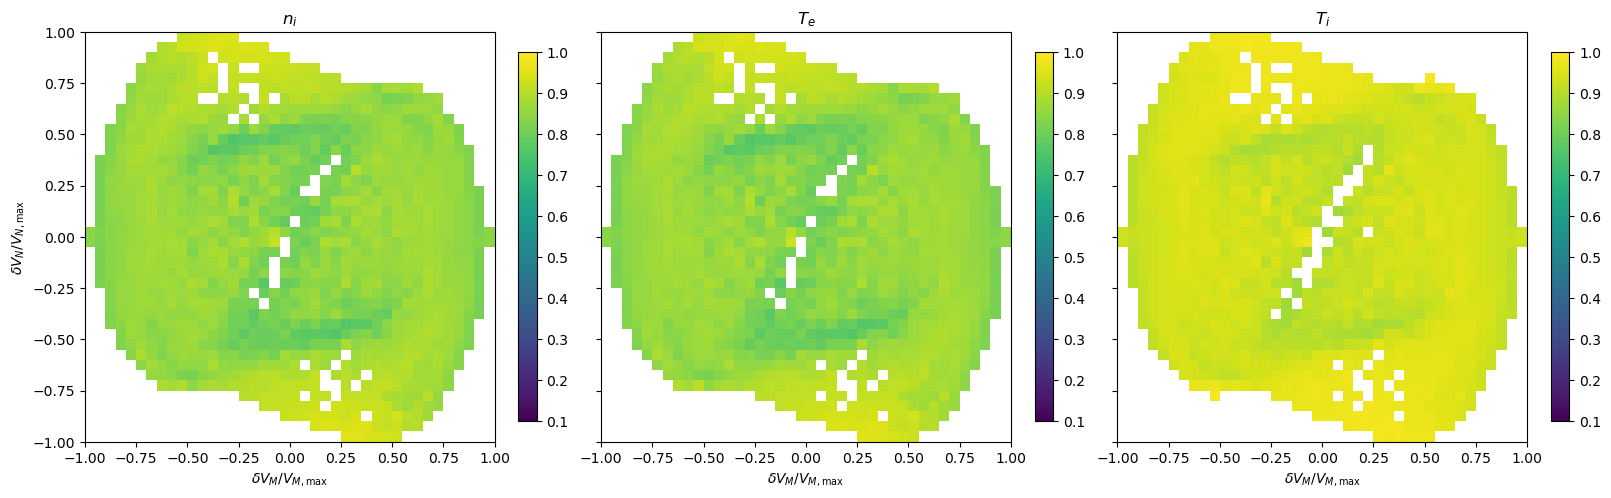

Saved /home/2480/nT_2D_step_lin.png


In [32]:
titles = [r"$n_i$", r"$T_e$", r"$T_i$"]
fig, axes = plt.subplots(
    1, 3, figsize=(16, 8), sharex=True, sharey=True,
    layout="constrained",
)
binned_results = {}

for ax, name, title in zip(axes, fields, titles):
    edges, Qmean, counts = velocity_binned_mean(
        vM, vN, Q_samples[name], bins=bins,
        min_count=min_count, percentile=percentile,
        normalize_Q=normalize_Q,
    )
    binned_results[name] = {"edges": edges, "mean": Qmean, "counts": counts}
    finite = Qmean[np.isfinite(Qmean)]
    if not finite.size:
        raise ValueError(f"All {name} bins are empty; reduce min_count, bins, or stride.")
    im = ax.pcolormesh(edges, edges, Qmean, cmap="viridis", vmin = 1e-1, vmax = 1)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel(r"$\delta V_M / V_{M,\max}$")
    cbar = fig.colorbar(im, ax=ax, location="right", fraction=0.045, pad=0.02, shrink=0.75)
    # cbar.set_label(r"$\langle Q/\max|Q|\rangle_{\rm bin}$" if normalize_Q
                #    else r"$\langle Q\rangle_{\rm bin}$ (simulation units)")

axes[0].set_ylabel(r"$\delta V_N / V_{N,\max}$")
time_label = ds.attrs.get("time", "unknown")
# fig.suptitle(f"Density and temperature | step={step}, time={time_label}")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved {output_path.resolve()}")